# 02 · Exploratory analysis and data quality
Class imbalance, document length, repeated entities, conflicting labels and split overlap.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT/'src'))
import pandas as pd
import numpy as np
def read_json(path): return json.loads((ROOT/path).read_text())

In [2]:
from IPython.display import display, Image
audit=read_json('reports/data_audit.json')
display(pd.DataFrame({name:{'rows':a['rows'],'unique_jds':a['unique_jds'],'unique_resumes':a['unique_resumes'],'duplicate_pairs':a['duplicate_pairs'],'conflicting_pairs':a['conflicting_pairs']} for name,a in audit.items() if name!='splits'}).T)
print(audit['splits'])

,rows,unique_jds,unique_resumes,duplicate_pairs,conflicting_pairs
original_train,6241,280,642,7,6
clean_train_full,6228,280,642,0,0
train,5025,224,634,0,0
validation,1203,56,460,0,0
test,1759,71,477,0,0


{'test_pairs_also_in_training': 0, 'test_jds_also_in_training': 0, 'test_resumes_also_in_training': 1758, 'train_validation_jd_overlap': 0, 'quarantined_rows': 12, 'policy': 'Quarantine conflicting normalized pairs in source train only, then deduplicate. Original test remains untouched.'}


In [3]:
train=pd.read_csv(ROOT/'data/processed/train.csv')
from resume_matcher.preprocessing import clean_text
display(train.label.value_counts().to_frame('pairs'))
display(pd.DataFrame({c:train[c].map(clean_text).str.split().str.len().describe() for c in ['resume_text','jd_text']}))

,pairs
label,
low_fit,2563
potential_fit,1249
strong_fit,1213


,resume_text,jd_text
count,5025.000000,5025.000000
mean,733.852338,375.925373
std,396.297634,242.757806
min,100.000000,11.000000
25%,513.000000,160.000000
50%,638.000000,332.000000
75%,836.000000,546.000000
max,3174.000000,1082.000000


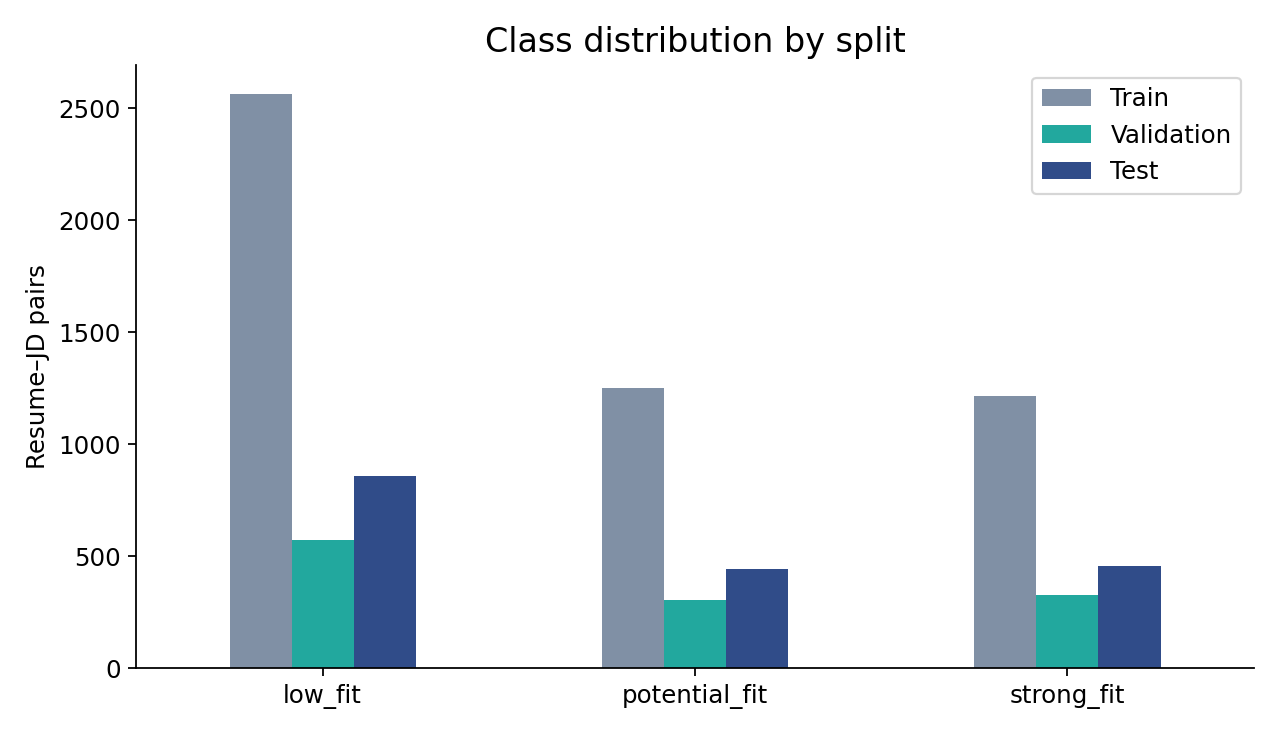

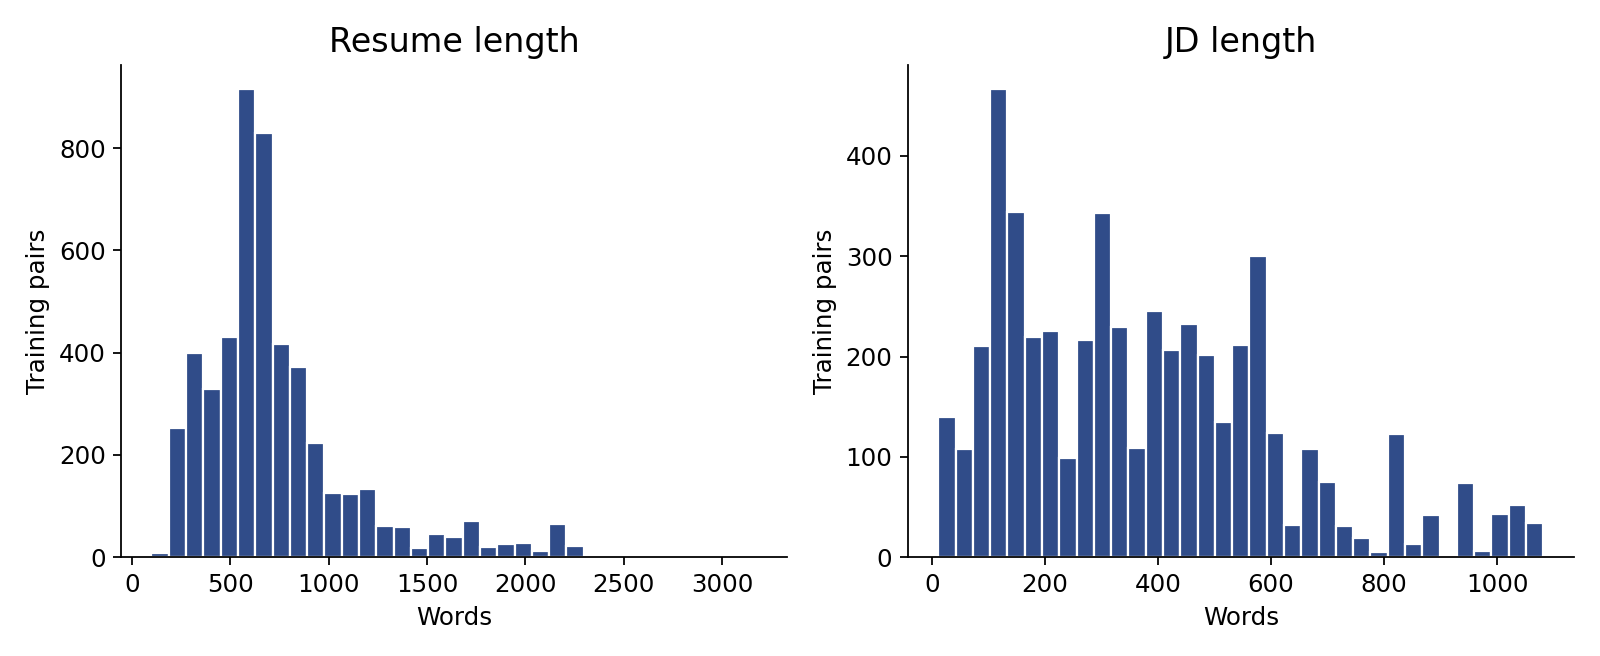

In [4]:
display(Image(filename=str(ROOT/'reports/figures/class_distribution.png')))
display(Image(filename=str(ROOT/'reports/figures/text_lengths.png')))

Low-fit dominates the labels. Use macro F1 alongside accuracy. Pair reuse makes random row splits optimistic for JD transfer. Long documents motivate chunked embeddings. Six contradictory pair groups require quarantine. The skill taxonomy is narrower than the dataset’s role coverage.